In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import wilcoxon, ttest_rel, mannwhitneyu, ttest_ind
import torch

from compcats.models import resnet50_imagenet1kv2, resnet50_random, vitb16_siglip2, resnet50_openaiclip, resnet101_openaiclip
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils, responsecomparison_utils as rcutils, reliability_utils as relutils

import main_analysis as ma
import paths

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/rigorous_testing_of_evidence'
os.makedirs(PLOTS_DIR, exist_ok=True)

pixdim[1,2,3] should be non-zero; setting 0 dims to 1


In [29]:
def get_bootstrapped_ceiling(subject_betas, n_bootstraps=100):
    # Estimate split-half reliability of the subject's responses (multivariate noise ceiling)
    noise_ceilings = []
    for _ in range(n_bootstraps):
        # For each stimuli, randomly split the repetitions into two halves and average the responses within each half
        # For each stimuli, assign two repetitions to one half and the remaining repetitions to the other half
        # There are a total of 3 repetitions per stimuli, so we can assign 2 repetitions to one half and 1 repetition to the other half
        half1_indices = []
        half2_indices = []
        for i in range(subject_betas.shape[0]):
            repetitions = torch.randperm(subject_betas.shape[1])
            half1_indices.append(repetitions[:2])
            half2_indices.append(repetitions[2:])
        half1_indices = torch.stack(half1_indices)
        half2_indices = torch.stack(half2_indices)
        # Average the responses within each half
        half1_betas = torch.stack([subject_betas[i, half1_indices[i]].mean(dim=0) for i in range(subject_betas.shape[0])])
        half2_betas = torch.stack([subject_betas[i, half2_indices[i]].mean(dim=0) for i in range(subject_betas.shape[0])])
        # Compute the correlation between the two halves across stimuli
        noise_ceiling = rcutils.rdmr(half1_betas, half2_betas)
        # Spearman-Brown correction to estimate the reliability of the full dataset (since we are using only half of the repetitions for each half)
        noise_ceiling = (2 * noise_ceiling) / (1 + noise_ceiling)
        noise_ceilings.append(noise_ceiling)
    noise_ceilings = torch.tensor(noise_ceilings)
    return noise_ceilings.median().item()

In [ ]:
froi = 'FFA'
tthreshold = 7
test_subset = 515
subjects = [1, 2, 3, 4, 5, 6, 7, 8]
n_bootstraps_ceiling = 100


Processing subject 1...
Processing subject 2...
Processing subject 3...
Processing subject 4...
Processing subject 5...
Processing subject 6...
Processing subject 7...
Processing subject 8...


Estimated noise ceiling: 0.533 ± 0.017
Baseline noise ceiling: 0.549


In [ ]:
vitsiglip2 = vitb16_siglip2.get_model()
rn50imgnet = resnet50_imagenet1kv2.get_model()
rn50rand = resnet50_random.get_model(seed=1)

models = {
    'ResNet-50 CLIP': resnet50_openaiclip.get_model(),
    'ResNet-101 CLIP': resnet101_openaiclip.get_model(),
    'ViT B/16 SigLIP-2': vitsiglip2,
    'ResNet-50 ImageNet': rn50imgnet,
    'ResNet-50 Random': rn50rand
}

model_localizer = 'grillspector'
model_localizer_dir = paths.GRILLSPECTOR_LOCALIZER_DIR



Initialized resnet50random1 with seed = 1


Comparing ceilings to ResNet-50 CLIP...
Mann-Whitney U test: statistic=176.000, p-value=0.013
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=6.000, p-value=0.109
Paired Wilcoxon signed-rank test: statistic=3.000, p-value=0.039


Comparing ceilings to ResNet-101 CLIP...
Mann-Whitney U test: statistic=205.000, p-value=0.000
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=3.000, p-value=0.039
Paired Wilcoxon signed-rank test: statistic=3.000, p-value=0.039


Comparing ceilings to ViT B/16 SigLIP-2...
Mann-Whitney U test: statistic=190.000, p-value=0.002
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=4.000, p-value=0.055
Paired Wilcoxon signed-rank test: statistic=2.000, p-value=0.023


Comparing ceilings to ResNet-50 ImageNet...
Mann-Whitney U test: statistic=197.000, p-value=0.001
Paired Wilcoxon signed-ra

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_83083/2602672149.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_83083/2602672149.py:88: UserWarning: 
The palette list has fewer values (8) than needed (9) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(


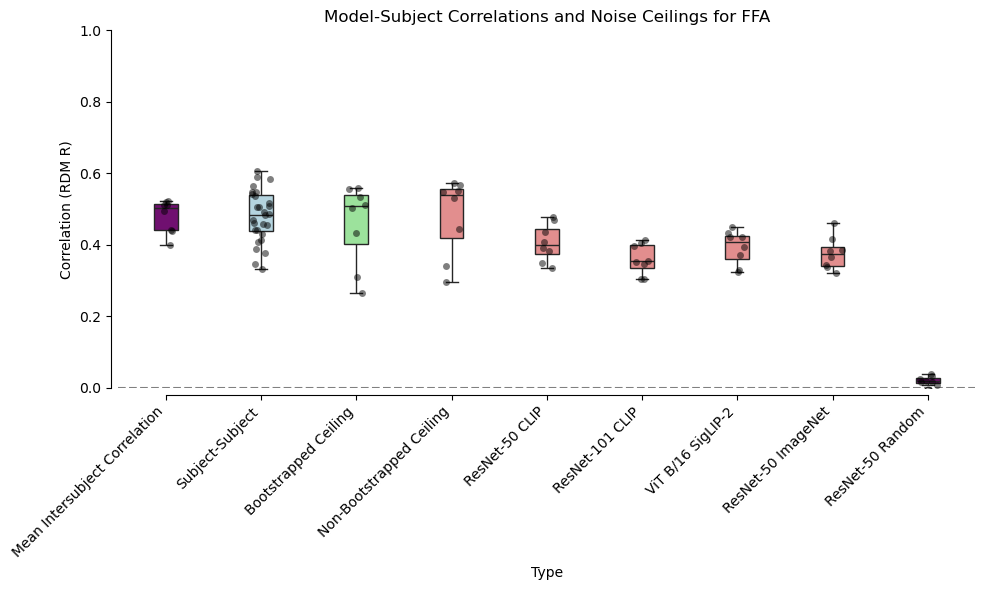

In [ ]:
subject_responses = {}
for subject in subjects:
    subject_betas, _ = nsd.get_betas(
        paths.NSD_DIR,
        subject,
        froi,
        tthreshold,
        test_subset,
        voxels=True,
        repetition_mean=False
    )
    subject_responses[subject] = subject_betas

bootstrapped_ceilings = {}
nonbootstrapped_ceilings = {}

for subject in subjects:
    print(f'Processing subject {subject}...')
    subject_betas = subject_responses[subject]
    bootstrapped_ceiling = get_bootstrapped_ceiling(subject_betas, n_bootstraps=n_bootstraps_ceiling)
    bootstrapped_ceilings[subject] = bootstrapped_ceiling
    nonbootstrapped_ceiling = relutils.get_rdm_splithalf_correlation(subject_betas)
    nonbootstrapped_ceilings[subject] = nonbootstrapped_ceiling
    # Average subject responses across repetitions
    subject_betas = subject_betas.mean(dim=1)
    subject_responses[subject] = subject_betas


model_responses = {}
for model_name, model in models.items():
    model_layer = ma.get_froi_models_layers(froi, froi)[model.name]
    model_responses[model_name] = model_utils.get_dataset_activations(
        MODELS_DIR, paths.NSD_DIR,
        model, model_layer, 
        'nsd', froi, tthreshold,
        model_localizer, model_localizer_dir, subset=test_subset
    )


model_subject_correlations = {}
for model_name, model_response in model_responses.items():
    model_subject_correlations[model_name] = {}
    for subject in subjects:
        subject_response = subject_responses[subject]
        correlation = rcutils.rdmr(subject_response.cpu(), model_response.cpu())
        model_subject_correlations[model_name][subject] = correlation

subject_subject_correlations = []
for i in range(len(subjects)):
    for j in range(i+1, len(subjects)):
        subject1 = subjects[i]
        subject2 = subjects[j]
        correlation = rcutils.rdmr(subject_responses[subject1].cpu(), subject_responses[subject2].cpu())
        subject_subject_correlations.append(correlation)

mean_intersubject_correlation = []
for subject in subjects:
    other_subjects = [s for s in subjects if s != subject]
    correlations = []
    for other_subject in other_subjects:
        correlation = rcutils.rdmr(subject_responses[subject].cpu(), subject_responses[other_subject].cpu())
        correlations.append(correlation)
    mean_intersubject_correlation.append(np.mean(correlations))

# Make a plot of the model-subject correlations and the noise ceilings for each subject
# Make boxplots, first is subject-subject correlations, then bootstrapped ceiling, then non-bootstrapped ceiling, and then the model-subject correlations for each model
plt.figure(figsize=(10, 6))
data = []
# Add subject-subject correlations
for correlation in subject_subject_correlations:
    data.append({
        'Subject': 'All',
        'Correlation': correlation,
        'Type': 'Subject-Subject'
    })

for subject in subjects:
    # Add mean intersubject correlation for this subject
    data.append({
        'Subject': subject,
        'Correlation': mean_intersubject_correlation[subject-1],
        'Type': 'Mean Intersubject Correlation'
    })
    data.append({
        'Subject': subject,
        'Correlation': bootstrapped_ceilings[subject],
        'Type': 'Bootstrapped Ceiling'
    })
    data.append({
        'Subject': subject,
        'Correlation': nonbootstrapped_ceilings[subject],
        'Type': 'Non-Bootstrapped Ceiling'
    })
    for model_name in models.keys():
        data.append({
            'Subject': subject,
            'Correlation': model_subject_correlations[model_name][subject],
            'Type': model_name
        })
df = pd.DataFrame(data)

# Conduct a paired Wilcoxon signed-rank test between the subject-subject correlations and each model-subject correlations for each model individually
for model_name in models.keys():
    print(f'Comparing ceilings to {model_name}...')
    stat, p = mannwhitneyu(
        subject_subject_correlations,
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Mann-Whitney U test: statistic={stat:.3f}, p-value={p:.3f}')
    # Also conduct a independent t-test for comparison
    # stat, p = ttest_ind(
    #     subject_subject_correlations,
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Independent t-test: statistic={stat:.3f}, p-value={p:.3f}')
    # Compare with mean intersubject correlation (Paired tests)
    stat, p = wilcoxon(
        mean_intersubject_correlation,
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Paired Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
    # stat, p = ttest_rel(
    #     mean_intersubject_correlation,
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Paired t-test: statistic={stat:.3f}, p-value={p:.3f}')
    # Compare with bootstrapped ceiling (Paired tests)
    stat, p = wilcoxon(
        [bootstrapped_ceilings[subject] for subject in subjects],
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Paired Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
    # stat, p = ttest_rel(
    #     [bootstrapped_ceilings[subject] for subject in subjects],
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Paired t-test: statistic={stat:.3f}, p-value={p:.3f}')
    # Compare with non-bootstrapped ceiling (Paired tests)
    stat, p = wilcoxon(
        [nonbootstrapped_ceilings[subject] for subject in subjects],
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Paired Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
    # stat, p = ttest_rel(
    #     [nonbootstrapped_ceilings[subject] for subject in subjects],
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Paired t-test: statistic={stat:.3f}, p-value={p:.3f}')
    print('\n')

plt.axhline(0, color='gray', linestyle='--')
sns.boxplot(
    x='Type', y='Correlation', data=df, 
    order=['Mean Intersubject Correlation', 'Subject-Subject', 'Bootstrapped Ceiling', 'Non-Bootstrapped Ceiling'] + list(models.keys()),
    width=0.25, palette=['purple', 'lightblue', 'lightgreen'] + ['lightcoral'] * len(models)
)
sns.stripplot(
    x='Type', y='Correlation', data=df, color='black', alpha=0.5, 
    order=['Mean Intersubject Correlation', 'Subject-Subject', 'Bootstrapped Ceiling', 'Non-Bootstrapped Ceiling'] + list(models.keys())
)
plt.title(f'Model-Subject Correlations and Noise Ceilings for {froi}')
plt.ylabel('Correlation (RDM R)')
plt.gca().set_ylim(0, 1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(models)+3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/model_subject_correlations_and_noise_ceilings.png')
plt.show()

Processing subject 1...
Processing subject 2...
Processing subject 3...
Processing subject 4...
Processing subject 5...
Processing subject 6...
Processing subject 7...
Processing subject 8...
Comparing ceilings to ResNet-50 CLIP...
Mann-Whitney U test: statistic=176.000, p-value=0.013
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=7.000, p-value=0.148
Paired Wilcoxon signed-rank test: statistic=3.000, p-value=0.039


Comparing ceilings to ResNet-101 CLIP...
Mann-Whitney U test: statistic=205.000, p-value=0.000
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=3.000, p-value=0.039
Paired Wilcoxon signed-rank test: statistic=3.000, p-value=0.039


Comparing ceilings to ViT B/16 SigLIP-2...
Mann-Whitney U test: statistic=190.000, p-value=0.002
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=4.000, p-value=0.05

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_83083/901602790.py:152: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_83083/901602790.py:152: UserWarning: 
The palette list has fewer values (8) than needed (9) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(


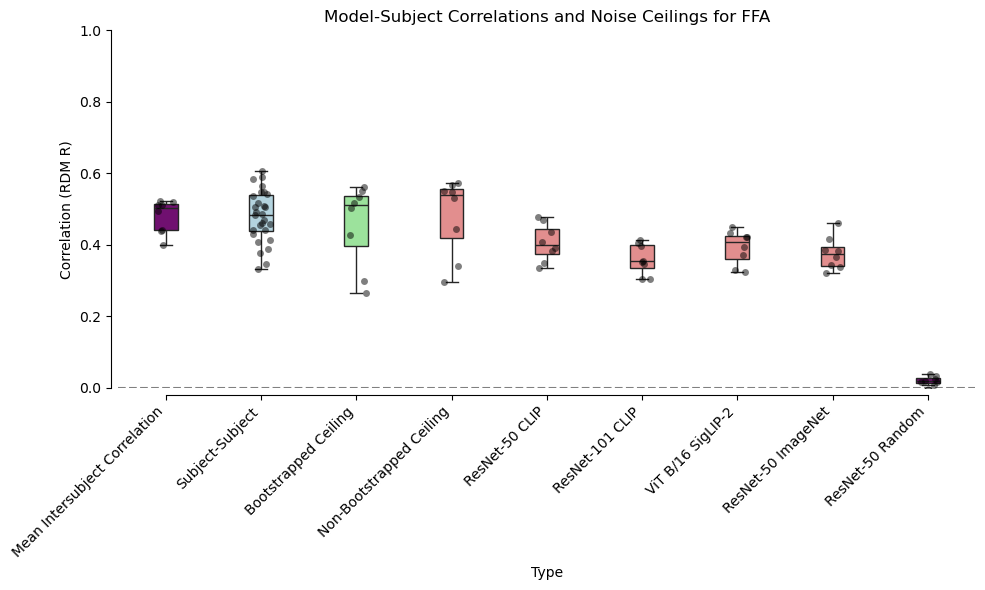

In [109]:
subject_responses = {}
for subject in subjects:
    subject_betas, _ = nsd.get_betas(
        paths.NSD_DIR,
        subject,
        froi,
        tthreshold,
        test_subset,
        voxels=True,
        repetition_mean=False
    )
    subject_responses[subject] = subject_betas

bootstrapped_ceilings = {}
nonbootstrapped_ceilings = {}

for subject in subjects:
    print(f'Processing subject {subject}...')
    subject_betas = subject_responses[subject]
    bootstrapped_ceiling = get_bootstrapped_ceiling(subject_betas, n_bootstraps=n_bootstraps_ceiling)
    bootstrapped_ceilings[subject] = bootstrapped_ceiling
    nonbootstrapped_ceiling = relutils.get_rdm_splithalf_correlation(subject_betas)
    nonbootstrapped_ceilings[subject] = nonbootstrapped_ceiling
    # Average subject responses across repetitions
    subject_betas = subject_betas.mean(dim=1)
    subject_responses[subject] = subject_betas


model_responses = {}
for model_name, model in models.items():
    model_layer = ma.get_froi_models_layers(froi, froi)[model.name]
    model_responses[model_name] = model_utils.get_dataset_activations(
        MODELS_DIR, paths.NSD_DIR,
        model, model_layer, 
        'nsd', froi, tthreshold,
        model_localizer, model_localizer_dir, subset=test_subset
    )


model_subject_correlations = {}
for model_name, model_response in model_responses.items():
    model_subject_correlations[model_name] = {}
    for subject in subjects:
        subject_response = subject_responses[subject]
        correlation = rcutils.rdmr(subject_response.cpu(), model_response.cpu())
        model_subject_correlations[model_name][subject] = correlation

subject_subject_correlations = []
for i in range(len(subjects)):
    for j in range(i+1, len(subjects)):
        subject1 = subjects[i]
        subject2 = subjects[j]
        correlation = rcutils.rdmr(subject_responses[subject1].cpu(), subject_responses[subject2].cpu())
        subject_subject_correlations.append(correlation)

mean_intersubject_correlation = []
for subject in subjects:
    other_subjects = [s for s in subjects if s != subject]
    correlations = []
    for other_subject in other_subjects:
        correlation = rcutils.rdmr(subject_responses[subject].cpu(), subject_responses[other_subject].cpu())
        correlations.append(correlation)
    mean_intersubject_correlation.append(np.mean(correlations))

# Make a plot of the model-subject correlations and the noise ceilings for each subject
# Make boxplots, first is subject-subject correlations, then bootstrapped ceiling, then non-bootstrapped ceiling, and then the model-subject correlations for each model
plt.figure(figsize=(10, 6))
data = []
# Add subject-subject correlations
for correlation in subject_subject_correlations:
    data.append({
        'Subject': 'All',
        'Correlation': correlation,
        'Type': 'Subject-Subject'
    })

for subject in subjects:
    # Add mean intersubject correlation for this subject
    data.append({
        'Subject': subject,
        'Correlation': mean_intersubject_correlation[subject-1],
        'Type': 'Mean Intersubject Correlation'
    })
    data.append({
        'Subject': subject,
        'Correlation': bootstrapped_ceilings[subject],
        'Type': 'Bootstrapped Ceiling'
    })
    data.append({
        'Subject': subject,
        'Correlation': nonbootstrapped_ceilings[subject],
        'Type': 'Non-Bootstrapped Ceiling'
    })
    for model_name in models.keys():
        data.append({
            'Subject': subject,
            'Correlation': model_subject_correlations[model_name][subject],
            'Type': model_name
        })
df = pd.DataFrame(data)

# Conduct a paired Wilcoxon signed-rank test between the subject-subject correlations and each model-subject correlations for each model individually
for model_name in models.keys():
    print(f'Comparing ceilings to {model_name}...')
    stat, p = mannwhitneyu(
        subject_subject_correlations,
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Mann-Whitney U test: statistic={stat:.3f}, p-value={p:.3f}')
    # Also conduct a independent t-test for comparison
    # stat, p = ttest_ind(
    #     subject_subject_correlations,
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Independent t-test: statistic={stat:.3f}, p-value={p:.3f}')
    # Compare with mean intersubject correlation (Paired tests)
    stat, p = wilcoxon(
        mean_intersubject_correlation,
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Paired Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
    # stat, p = ttest_rel(
    #     mean_intersubject_correlation,
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Paired t-test: statistic={stat:.3f}, p-value={p:.3f}')
    # Compare with bootstrapped ceiling (Paired tests)
    stat, p = wilcoxon(
        [bootstrapped_ceilings[subject] for subject in subjects],
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Paired Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
    # stat, p = ttest_rel(
    #     [bootstrapped_ceilings[subject] for subject in subjects],
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Paired t-test: statistic={stat:.3f}, p-value={p:.3f}')
    # Compare with non-bootstrapped ceiling (Paired tests)
    stat, p = wilcoxon(
        [nonbootstrapped_ceilings[subject] for subject in subjects],
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Paired Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
    # stat, p = ttest_rel(
    #     [nonbootstrapped_ceilings[subject] for subject in subjects],
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Paired t-test: statistic={stat:.3f}, p-value={p:.3f}')
    print('\n')

plt.axhline(0, color='gray', linestyle='--')
sns.boxplot(
    x='Type', y='Correlation', data=df, 
    order=['Mean Intersubject Correlation', 'Subject-Subject', 'Bootstrapped Ceiling', 'Non-Bootstrapped Ceiling'] + list(models.keys()),
    width=0.25, palette=['purple', 'lightblue', 'lightgreen'] + ['lightcoral'] * len(models)
)
sns.stripplot(
    x='Type', y='Correlation', data=df, color='black', alpha=0.5, 
    order=['Mean Intersubject Correlation', 'Subject-Subject', 'Bootstrapped Ceiling', 'Non-Bootstrapped Ceiling'] + list(models.keys())
)
plt.title(f'Model-Subject Correlations and Noise Ceilings for {froi}')
plt.ylabel('Correlation (RDM R)')
plt.gca().set_ylim(0, 1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(models)+3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/model_subject_correlations_and_noise_ceilings.png')
plt.show()

Processing subject 1...
Processing subject 2...
Processing subject 3...
Processing subject 4...
Processing subject 5...
Processing subject 6...
Processing subject 7...
Processing subject 8...
Comparing ceilings to ResNet-50 CLIP...
Mann-Whitney U test: statistic=216.000, p-value=0.000
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=6.000, p-value=0.109
Paired Wilcoxon signed-rank test: statistic=3.000, p-value=0.039


Comparing ceilings to ResNet-101 CLIP...
Mann-Whitney U test: statistic=224.000, p-value=0.000
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008


Comparing ceilings to ViT B/16 SigLIP-2...
Mann-Whitney U test: statistic=223.000, p-value=0.000
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.00

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_83083/896343266.py:154: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_83083/896343266.py:154: UserWarning: 
The palette list has fewer values (8) than needed (9) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(


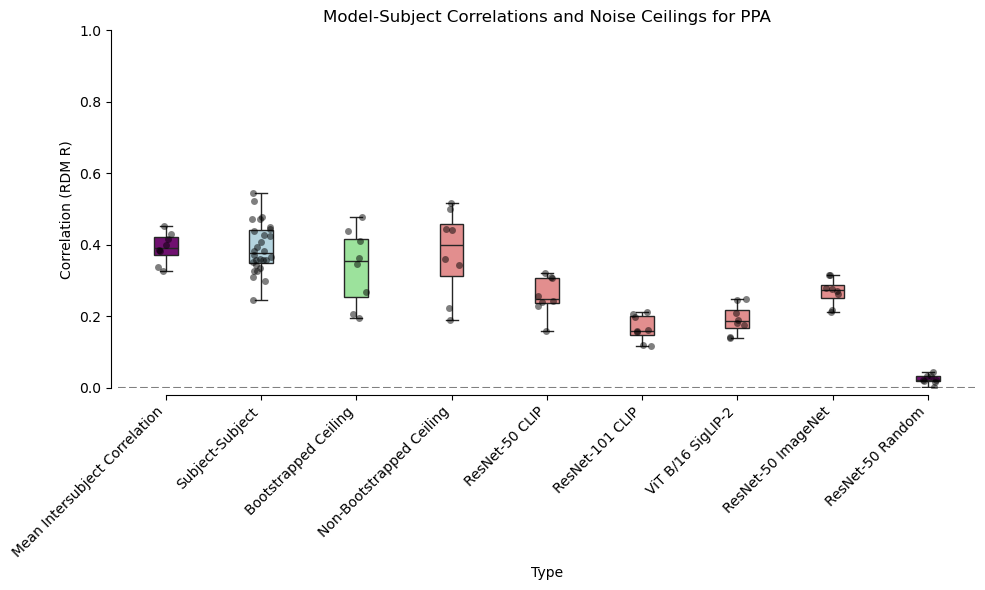

In [110]:
froi = 'PPA'

subject_responses = {}
for subject in subjects:
    subject_betas, _ = nsd.get_betas(
        paths.NSD_DIR,
        subject,
        froi,
        tthreshold,
        test_subset,
        voxels=True,
        repetition_mean=False
    )
    subject_responses[subject] = subject_betas

bootstrapped_ceilings = {}
nonbootstrapped_ceilings = {}

for subject in subjects:
    print(f'Processing subject {subject}...')
    subject_betas = subject_responses[subject]
    bootstrapped_ceiling = get_bootstrapped_ceiling(subject_betas, n_bootstraps=n_bootstraps_ceiling)
    bootstrapped_ceilings[subject] = bootstrapped_ceiling
    nonbootstrapped_ceiling = relutils.get_rdm_splithalf_correlation(subject_betas)
    nonbootstrapped_ceilings[subject] = nonbootstrapped_ceiling
    # Average subject responses across repetitions
    subject_betas = subject_betas.mean(dim=1)
    subject_responses[subject] = subject_betas


model_responses = {}
for model_name, model in models.items():
    model_layer = ma.get_froi_models_layers(froi, froi)[model.name]
    model_responses[model_name] = model_utils.get_dataset_activations(
        MODELS_DIR, paths.NSD_DIR,
        model, model_layer, 
        'nsd', froi, tthreshold,
        model_localizer, model_localizer_dir, subset=test_subset
    )


model_subject_correlations = {}
for model_name, model_response in model_responses.items():
    model_subject_correlations[model_name] = {}
    for subject in subjects:
        subject_response = subject_responses[subject]
        correlation = rcutils.rdmr(subject_response.cpu(), model_response.cpu())
        model_subject_correlations[model_name][subject] = correlation

subject_subject_correlations = []
for i in range(len(subjects)):
    for j in range(i+1, len(subjects)):
        subject1 = subjects[i]
        subject2 = subjects[j]
        correlation = rcutils.rdmr(subject_responses[subject1].cpu(), subject_responses[subject2].cpu())
        subject_subject_correlations.append(correlation)

mean_intersubject_correlation = []
for subject in subjects:
    other_subjects = [s for s in subjects if s != subject]
    correlations = []
    for other_subject in other_subjects:
        correlation = rcutils.rdmr(subject_responses[subject].cpu(), subject_responses[other_subject].cpu())
        correlations.append(correlation)
    mean_intersubject_correlation.append(np.mean(correlations))

# Make a plot of the model-subject correlations and the noise ceilings for each subject
# Make boxplots, first is subject-subject correlations, then bootstrapped ceiling, then non-bootstrapped ceiling, and then the model-subject correlations for each model
plt.figure(figsize=(10, 6))
data = []
# Add subject-subject correlations
for correlation in subject_subject_correlations:
    data.append({
        'Subject': 'All',
        'Correlation': correlation,
        'Type': 'Subject-Subject'
    })

for subject in subjects:
    # Add mean intersubject correlation for this subject
    data.append({
        'Subject': subject,
        'Correlation': mean_intersubject_correlation[subject-1],
        'Type': 'Mean Intersubject Correlation'
    })
    data.append({
        'Subject': subject,
        'Correlation': bootstrapped_ceilings[subject],
        'Type': 'Bootstrapped Ceiling'
    })
    data.append({
        'Subject': subject,
        'Correlation': nonbootstrapped_ceilings[subject],
        'Type': 'Non-Bootstrapped Ceiling'
    })
    for model_name in models.keys():
        data.append({
            'Subject': subject,
            'Correlation': model_subject_correlations[model_name][subject],
            'Type': model_name
        })
df = pd.DataFrame(data)

# Conduct a paired Wilcoxon signed-rank test between the subject-subject correlations and each model-subject correlations for each model individually
for model_name in models.keys():
    print(f'Comparing ceilings to {model_name}...')
    stat, p = mannwhitneyu(
        subject_subject_correlations,
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Mann-Whitney U test: statistic={stat:.3f}, p-value={p:.3f}')
    # Also conduct a independent t-test for comparison
    # stat, p = ttest_ind(
    #     subject_subject_correlations,
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Independent t-test: statistic={stat:.3f}, p-value={p:.3f}')
    # Compare with mean intersubject correlation (Paired tests)
    stat, p = wilcoxon(
        mean_intersubject_correlation,
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Paired Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
    # stat, p = ttest_rel(
    #     mean_intersubject_correlation,
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Paired t-test: statistic={stat:.3f}, p-value={p:.3f}')
    # Compare with bootstrapped ceiling (Paired tests)
    stat, p = wilcoxon(
        [bootstrapped_ceilings[subject] for subject in subjects],
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Paired Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
    # stat, p = ttest_rel(
    #     [bootstrapped_ceilings[subject] for subject in subjects],
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Paired t-test: statistic={stat:.3f}, p-value={p:.3f}')
    # Compare with non-bootstrapped ceiling (Paired tests)
    stat, p = wilcoxon(
        [nonbootstrapped_ceilings[subject] for subject in subjects],
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Paired Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
    # stat, p = ttest_rel(
    #     [nonbootstrapped_ceilings[subject] for subject in subjects],
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Paired t-test: statistic={stat:.3f}, p-value={p:.3f}')
    print('\n')

plt.axhline(0, color='gray', linestyle='--')
sns.boxplot(
    x='Type', y='Correlation', data=df, 
    order=['Mean Intersubject Correlation', 'Subject-Subject', 'Bootstrapped Ceiling', 'Non-Bootstrapped Ceiling'] + list(models.keys()),
    width=0.25, palette=['purple', 'lightblue', 'lightgreen'] + ['lightcoral'] * len(models)
)
sns.stripplot(
    x='Type', y='Correlation', data=df, color='black', alpha=0.5, 
    order=['Mean Intersubject Correlation', 'Subject-Subject', 'Bootstrapped Ceiling', 'Non-Bootstrapped Ceiling'] + list(models.keys())
)
plt.title(f'Model-Subject Correlations and Noise Ceilings for {froi}')
plt.ylabel('Correlation (RDM R)')
plt.gca().set_ylim(0, 1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(models)+3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/model_subject_correlations_and_noise_ceilings.png')
plt.show()

Processing subject 1...
Processing subject 2...
Processing subject 3...
Processing subject 4...
Processing subject 5...
Processing subject 6...
Processing subject 7...
Processing subject 8...
Comparing ceilings to ResNet-50 CLIP...
Mann-Whitney U test: statistic=224.000, p-value=0.000
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=1.000, p-value=0.016
Paired Wilcoxon signed-rank test: statistic=1.000, p-value=0.016


Comparing ceilings to ResNet-101 CLIP...
Mann-Whitney U test: statistic=189.000, p-value=0.002
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=7.000, p-value=0.148
Paired Wilcoxon signed-rank test: statistic=7.000, p-value=0.148


Comparing ceilings to ViT B/16 SigLIP-2...
Mann-Whitney U test: statistic=210.000, p-value=0.000
Paired Wilcoxon signed-rank test: statistic=0.000, p-value=0.008
Paired Wilcoxon signed-rank test: statistic=6.000, p-value=0.10

/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_83083/2976643300.py:154: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/f4/jrx4_ljx4_q3d25kvtsnw4tw0000gq/T/ipykernel_83083/2976643300.py:154: UserWarning: 
The palette list has fewer values (8) than needed (9) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(


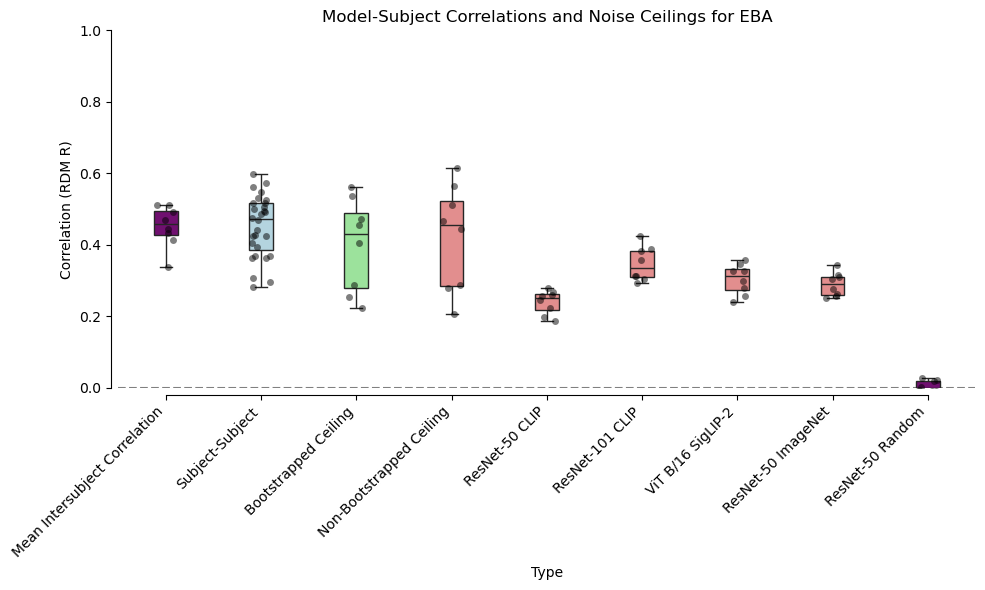

In [111]:
froi = 'EBA'

subject_responses = {}
for subject in subjects:
    subject_betas, _ = nsd.get_betas(
        paths.NSD_DIR,
        subject,
        froi,
        tthreshold,
        test_subset,
        voxels=True,
        repetition_mean=False
    )
    subject_responses[subject] = subject_betas

bootstrapped_ceilings = {}
nonbootstrapped_ceilings = {}

for subject in subjects:
    print(f'Processing subject {subject}...')
    subject_betas = subject_responses[subject]
    bootstrapped_ceiling = get_bootstrapped_ceiling(subject_betas, n_bootstraps=n_bootstraps_ceiling)
    bootstrapped_ceilings[subject] = bootstrapped_ceiling
    nonbootstrapped_ceiling = relutils.get_rdm_splithalf_correlation(subject_betas)
    nonbootstrapped_ceilings[subject] = nonbootstrapped_ceiling
    # Average subject responses across repetitions
    subject_betas = subject_betas.mean(dim=1)
    subject_responses[subject] = subject_betas


model_responses = {}
for model_name, model in models.items():
    model_layer = ma.get_froi_models_layers(froi, froi)[model.name]
    model_responses[model_name] = model_utils.get_dataset_activations(
        MODELS_DIR, paths.NSD_DIR,
        model, model_layer, 
        'nsd', froi, tthreshold,
        model_localizer, model_localizer_dir, subset=test_subset
    )


model_subject_correlations = {}
for model_name, model_response in model_responses.items():
    model_subject_correlations[model_name] = {}
    for subject in subjects:
        subject_response = subject_responses[subject]
        correlation = rcutils.rdmr(subject_response.cpu(), model_response.cpu())
        model_subject_correlations[model_name][subject] = correlation

subject_subject_correlations = []
for i in range(len(subjects)):
    for j in range(i+1, len(subjects)):
        subject1 = subjects[i]
        subject2 = subjects[j]
        correlation = rcutils.rdmr(subject_responses[subject1].cpu(), subject_responses[subject2].cpu())
        subject_subject_correlations.append(correlation)

mean_intersubject_correlation = []
for subject in subjects:
    other_subjects = [s for s in subjects if s != subject]
    correlations = []
    for other_subject in other_subjects:
        correlation = rcutils.rdmr(subject_responses[subject].cpu(), subject_responses[other_subject].cpu())
        correlations.append(correlation)
    mean_intersubject_correlation.append(np.mean(correlations))

# Make a plot of the model-subject correlations and the noise ceilings for each subject
# Make boxplots, first is subject-subject correlations, then bootstrapped ceiling, then non-bootstrapped ceiling, and then the model-subject correlations for each model
plt.figure(figsize=(10, 6))
data = []
# Add subject-subject correlations
for correlation in subject_subject_correlations:
    data.append({
        'Subject': 'All',
        'Correlation': correlation,
        'Type': 'Subject-Subject'
    })

for subject in subjects:
    # Add mean intersubject correlation for this subject
    data.append({
        'Subject': subject,
        'Correlation': mean_intersubject_correlation[subject-1],
        'Type': 'Mean Intersubject Correlation'
    })
    data.append({
        'Subject': subject,
        'Correlation': bootstrapped_ceilings[subject],
        'Type': 'Bootstrapped Ceiling'
    })
    data.append({
        'Subject': subject,
        'Correlation': nonbootstrapped_ceilings[subject],
        'Type': 'Non-Bootstrapped Ceiling'
    })
    for model_name in models.keys():
        data.append({
            'Subject': subject,
            'Correlation': model_subject_correlations[model_name][subject],
            'Type': model_name
        })
df = pd.DataFrame(data)

# Conduct a paired Wilcoxon signed-rank test between the subject-subject correlations and each model-subject correlations for each model individually
for model_name in models.keys():
    print(f'Comparing ceilings to {model_name}...')
    stat, p = mannwhitneyu(
        subject_subject_correlations,
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Mann-Whitney U test: statistic={stat:.3f}, p-value={p:.3f}')
    # Also conduct a independent t-test for comparison
    # stat, p = ttest_ind(
    #     subject_subject_correlations,
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Independent t-test: statistic={stat:.3f}, p-value={p:.3f}')
    # Compare with mean intersubject correlation (Paired tests)
    stat, p = wilcoxon(
        mean_intersubject_correlation,
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Paired Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
    # stat, p = ttest_rel(
    #     mean_intersubject_correlation,
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Paired t-test: statistic={stat:.3f}, p-value={p:.3f}')
    # Compare with bootstrapped ceiling (Paired tests)
    stat, p = wilcoxon(
        [bootstrapped_ceilings[subject] for subject in subjects],
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Paired Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
    # stat, p = ttest_rel(
    #     [bootstrapped_ceilings[subject] for subject in subjects],
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Paired t-test: statistic={stat:.3f}, p-value={p:.3f}')
    # Compare with non-bootstrapped ceiling (Paired tests)
    stat, p = wilcoxon(
        [nonbootstrapped_ceilings[subject] for subject in subjects],
        [model_subject_correlations[model_name][subject] for subject in subjects]
    )
    print(f'Paired Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
    # stat, p = ttest_rel(
    #     [nonbootstrapped_ceilings[subject] for subject in subjects],
    #     [model_subject_correlations[model_name][subject] for subject in subjects]
    # )
    # print(f'Paired t-test: statistic={stat:.3f}, p-value={p:.3f}')
    print('\n')

plt.axhline(0, color='gray', linestyle='--')
sns.boxplot(
    x='Type', y='Correlation', data=df, 
    order=['Mean Intersubject Correlation', 'Subject-Subject', 'Bootstrapped Ceiling', 'Non-Bootstrapped Ceiling'] + list(models.keys()),
    width=0.25, palette=['purple', 'lightblue', 'lightgreen'] + ['lightcoral'] * len(models)
)
sns.stripplot(
    x='Type', y='Correlation', data=df, color='black', alpha=0.5, 
    order=['Mean Intersubject Correlation', 'Subject-Subject', 'Bootstrapped Ceiling', 'Non-Bootstrapped Ceiling'] + list(models.keys())
)
plt.title(f'Model-Subject Correlations and Noise Ceilings for {froi}')
plt.ylabel('Correlation (RDM R)')
plt.gca().set_ylim(0, 1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(models)+3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/model_subject_correlations_and_noise_ceilings.png')
plt.show()

In [71]:
display_subjects1 = [1, 2, 5, 7]
display_subjects2 = [1, 2, 3, 4, 5, 6, 7, 8]
display_subjects = display_subjects1
bootstrapped_ceiling_slice = df[
    (df['Type'] == 'Bootstrapped Ceiling') &
    (df['Subject'].isin(display_subjects))
]
nonbootstrapped_ceiling_slice = df[
    (df['Type'] == 'Non-Bootstrapped Ceiling') &
    (df['Subject'].isin(display_subjects))
]
model_name = 'ResNet-50 CLIP'
model_slice = df[
    (df['Type'] == model_name) &
    (df['Subject'].isin(display_subjects))
]
# Join the three slices into a single dataframe for display, make 3 columns, one for each type, and the values are the correlations
display_df = pd.DataFrame({
    'Subject': display_subjects,
    'Bootstrapped Ceiling': bootstrapped_ceiling_slice['Correlation'].values,
    'Non-Bootstrapped Ceiling': nonbootstrapped_ceiling_slice['Correlation'].values,
    model_name: model_slice['Correlation'].values
})
display(display_df)
# display(df[
#     (df['Type'] == 'ResNet-50 CLIP') &
#     (df['Subject'].isin(display_subjects))
# ])
# display(df[
#     (df['Type'] == 'Bootstrapped Ceiling') &
#     (df['Subject'].isin(display_subjects))
# ])
# display(
#     df[
#         (df['Type'] == 'Non-Bootstrapped Ceiling') &
#         (df['Subject'].isin(display_subjects))
# ])

,Subject,Bootstrapped Ceiling,Non-Bootstrapped Ceiling,ResNet-50 CLIP
0,1,0.534882,0.549200,0.382097
1,2,0.555169,0.573563,0.436343
2,5,0.512573,0.550638,0.408328
3,7,0.264452,0.297377,0.336149


In [82]:
print('Subject-subject correlation median:', np.median(subject_subject_correlations))
print('Within subject bootstrapped correlation median:', np.median(df[df['Type'] == 'Bootstrapped Ceiling']['Correlation'].values))
print('Within subject non-bootstrapped correlation median:', np.median(df[df['Type'] == 'Non-Bootstrapped Ceiling']['Correlation'].values))
print('Model-subject correlation median for ResNet-50 CLIP:', np.median(df[df['Type'] == 'ResNet-50 CLIP']['Correlation'].values))

Subject-subject correlation median: 0.484948068857193
Within subject bootstrapped correlation median: 0.5079574882984161
Within subject non-bootstrapped correlation median: 0.5398795346938599
Model-subject correlation median for ResNet-50 CLIP: 0.3998541831970215


In [108]:
emdf = pd.read_csv('/Users/adipani3/projects/catsel/comparing-category-selectivity/preprint/results/layer_froi_lesion_ems_fixedalpha.csv')
emdf_slice = emdf[
    (emdf['fmri_froi'] == froi) &
    (emdf['mapper'] == 'ridge') &
    (emdf['model'] == 'resnet50openaiclip')
]
stat, p = wilcoxon(
    emdf_slice['fmri_splithalf_rdmr'],
    emdf_slice['layer_raw_rdmr']
)
print(f'Full layer: Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
stat, p = wilcoxon(
    emdf_slice['fmri_splithalf_rdmr'],
    emdf_slice['lesion_raw_rdmr']
)
print(f'Lesioned: Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
stat, p = wilcoxon(
    emdf_slice['fmri_splithalf_rdmr'],
    emdf_slice['froi_raw_rdmr']
)
print(f'Only: Wilcoxon signed-rank test: statistic={stat:.3f}, p-value={p:.3f}')
# emdf_slice_rdmr_delta = emdf_slice['fmri_splithalf_rdmr'] - emdf_slice['layer_raw_rdmr']
# print(emdf_slice_rdmr_delta)

Full layer: Wilcoxon signed-rank test: statistic=1.000, p-value=0.250
Lesioned: Wilcoxon signed-rank test: statistic=1.000, p-value=0.250
Only: Wilcoxon signed-rank test: statistic=0.000, p-value=0.125


In [105]:
emdf_slice

,model,subject,layer,model_froi,fmri_froi,model_tthreshold,fmri_tthreshold,model_localizer,mapper,alpha,...,fmri_splithalf_rdmr,n_units_layer,n_units_lesioned,percent_units_lesioned,layer_raw_pearsonr,layer_raw_rdmr,froi_raw_pearsonr,froi_raw_rdmr,lesion_raw_pearsonr,lesion_raw_rdmr
8,resnet50openaiclip,1,layer4.1.relu1,FFA,FFA,7,7,grillspector,ridge,0.1,...,0.549200,25088,816,3.252551,0.838582,0.641043,0.648133,0.391601,0.833506,0.632190
43,resnet50openaiclip,2,layer4.1.relu1,FFA,FFA,7,7,grillspector,ridge,0.1,...,0.573563,25088,816,3.252551,0.826329,0.627339,0.634615,0.404873,0.816368,0.611917
78,resnet50openaiclip,5,layer4.1.relu1,FFA,FFA,7,7,grillspector,ridge,0.1,...,0.550638,25088,816,3.252551,0.769460,0.546531,0.562109,0.355876,0.763856,0.532220
113,resnet50openaiclip,7,layer4.1.relu1,FFA,FFA,7,7,grillspector,ridge,0.1,...,0.297377,25088,816,3.252551,0.707570,0.458780,0.468454,0.278741,0.701127,0.448828
